In [7]:
import numpy as np
import re 
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import os
import pandas as pd


In [2]:
def data_from_filename(folder):
    rows = []   

    # Listar archivos en el folder
    for file in os.listdir(folder): 
        
        # Extraer parametros del filename
        m = re.search(r"_L(\d+)_T([0-9.]+)_N\d+_([0-1])", file) 
        if not m:
            continue

        # Guardar en DataFrame
        L, T, class_ = m.groups() 
        rows.append({
            'file': file,
            'L': int(L),
            'T': float(T),
            'class': int(class_)
        })

    return pd.DataFrame(rows, columns=['file', 'L', 'T', 'class'])

files = data_from_filename('./../data/')

In [18]:
# Obtener distribución de determinada función.
def read_file(file, L, function):

    # Leer archivo
    with open(file, 'r') as f:
        lines = f.readlines()

    # Leer metadata y redes de espines
    metadata = lines[0] #Todo: Convertir metadata a key - value
    spins = lines[1:] 

    distribution = []
    for spin in spins:
        array = np.array(spin[:-1].split(',')).astype(int).reshape(L, L)
        distribution.append(function(array))

    return distribution



# Energía

In [4]:
# Cálculo de la energía total del sistema
def energy(spin, J=1, H=0):

    L = spin.shape[0]
    
    # Término de interacción entre primeros vecinos
    interaction_energy = 0.0
    
    # Interacciones horizontales (hacia la derecha)
    interaction_energy -= J * np.sum(spin[:, :-1] * spin[:, 1:])
    interaction_energy -= J * np.sum(spin[:, -1] * spin[:, 0])  # Condición periódica
    
    # Interacciones verticales (hacia abajo)
    interaction_energy -= J * np.sum(spin[:-1, :] * spin[1:, :])
    interaction_energy -= J * np.sum(spin[-1, :] * spin[0, :])  # Condición periódica
    
    # Término del campo magnético externo
    field_energy = -H * np.sum(spin)
    
    return interaction_energy + field_energy


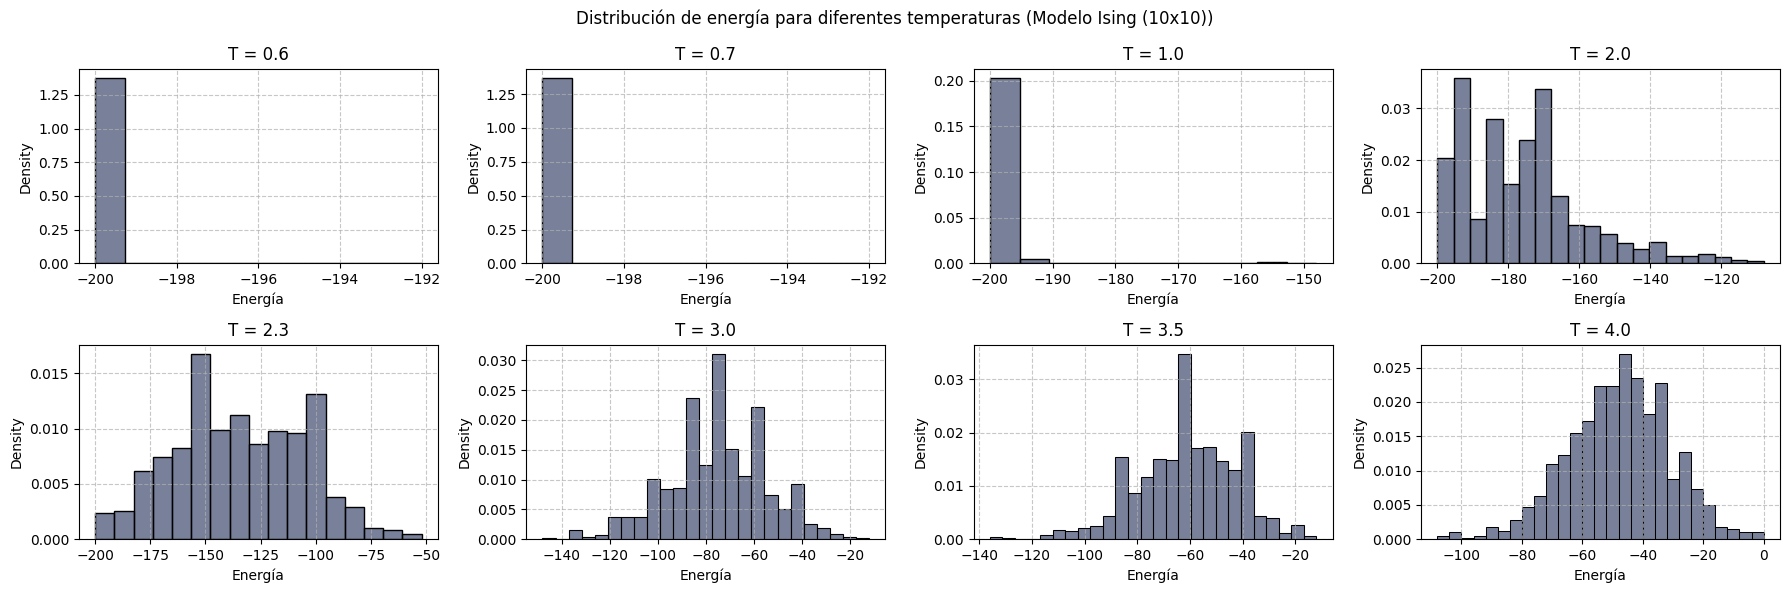

In [32]:
T = [0.6, 0.7, 1.0, 2.0, 2.3, 3.0, 3.5, 4.0]

# Crear la figura y la grilla 
fig = plt.figure(figsize=(18, 6))
gs = gridspec.GridSpec(2, 4)

for i in range(8):
    ax = fig.add_subplot(gs[i])
    filename = files.loc[files['T'] == T[i]]['file'].values[0] # Loc ising spin distributions
    energy_distribution = read_file('./../data/' + filename, 10, function=energy) # Read and calculate energy distribution

    sns.histplot(energy_distribution, ax=ax, color="#3f4b6f", alpha=0.7, stat="density")
    ax.set_title(f"T = {T[i]}")
    ax.set_xlabel('Energía')
    ax.grid(True, linestyle="--", alpha=0.7)

fig.suptitle("Distribución de energía para diferentes temperaturas (Modelo Ising (10x10))")

plt.tight_layout()
plt.show()


# Magenización

In [34]:
# Magnetización
def magnetization(spin):
    return np.sum(spin)


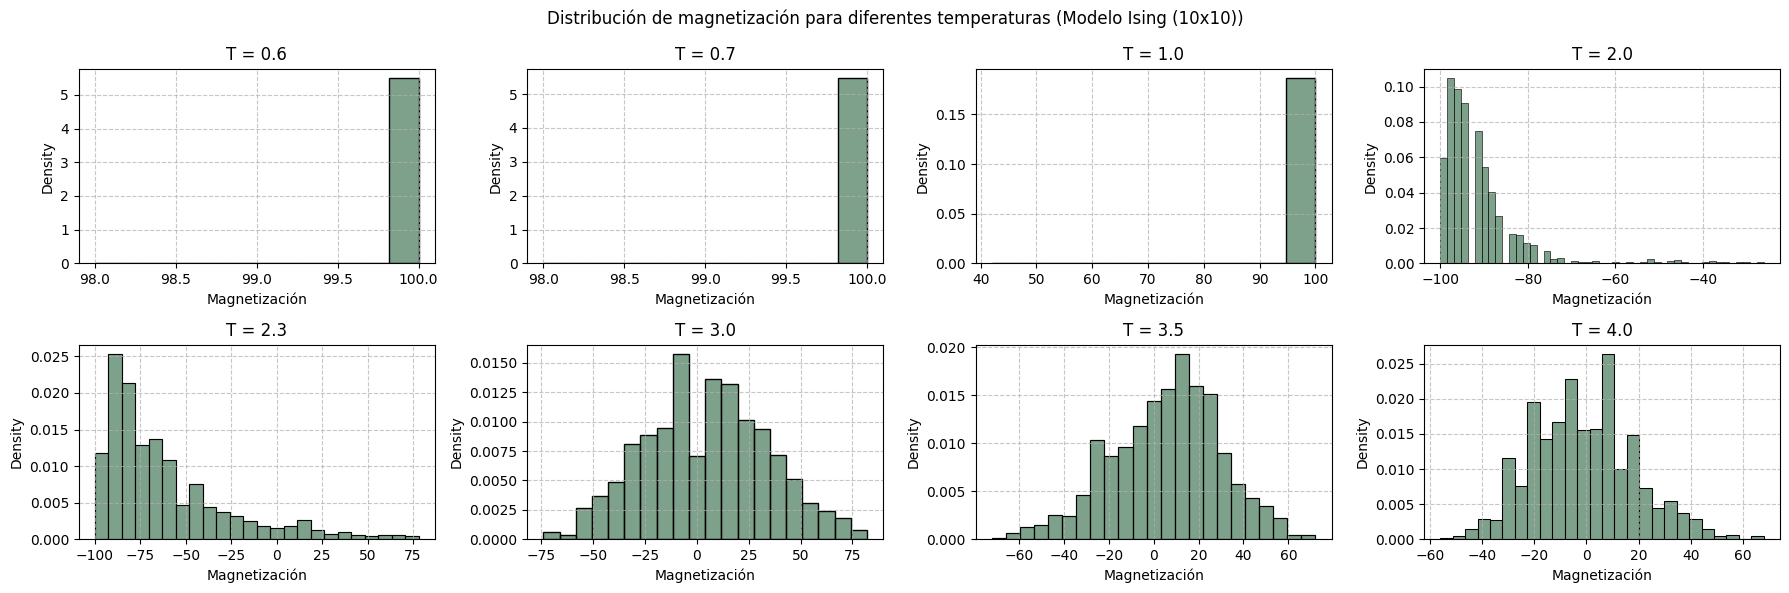

In [37]:
T = [0.6, 0.7, 1.0, 2.0, 2.3, 3.0, 3.5, 4.0]

# Crear la figura y la grilla 
fig = plt.figure(figsize=(18, 6))
gs = gridspec.GridSpec(2, 4)

for i in range(8):
    ax = fig.add_subplot(gs[i])
    filename = files.loc[files['T'] == T[i]]['file'].values[0] # Loc ising spin distributions
    energy_distribution = read_file('./../data/' + filename, 10, function=magnetization) # Read and calculate energy distribution

    sns.histplot(energy_distribution, ax=ax, color="#47795a", alpha=0.7, stat="density")
    ax.set_title(f"T = {T[i]}")
    ax.set_xlabel('Magnetización')
    ax.grid(True, linestyle="--", alpha=0.7)

fig.suptitle("Distribución de magnetización para diferentes temperaturas (Modelo Ising (10x10))")

plt.tight_layout()
plt.show()
